In [2]:
import numpy as np
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from tensorflow.keras import layers
from tensorflow.keras.models import load_model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [3]:
import os

DATA_DIR = "Skin Disease Dataset"   # same path you used earlier

classes = sorted(os.listdir(DATA_DIR))
num_classes = len(classes)

print("Classes:", classes)
print("Number of classes:", num_classes)


Classes: ['Acitinic Keratosis', 'Dermatofibroma', 'Nevus', 'Pigmented Benign Keratosis', 'Seborrheic Keratosis', 'Vascular Lesion']
Number of classes: 6


In [4]:
import cv2
from collections import defaultdict
from tqdm import tqdm
IMG_SIZE = 224
data_dict = defaultdict(list)
root_images = []
root_labels = []
error_count = 0

for class_name in classes:
    class_path = os.path.join(DATA_DIR, class_name)
    images = os.listdir(class_path)

    for img_name in tqdm(images, desc=f"Loading {class_name}"):
        try:
            img_path = os.path.join(class_path, img_name)
            image = cv2.imread(img_path)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            data_dict[class_name].append(image)
            root_images.append(image)
            root_labels.append(class_name)
        except:
            error_count += 1

print("Errors:", error_count)
print("Total images loaded:", len(root_images))

Loading Vascular Lesion: 100%|██████████| 290/290 [00:04<00:00, 58.86it/s] 

Errors: 2
Total images loaded: 2688


Acitinic Keratosis            500
Nevus                         500
Pigmented Benign Keratosis    500
Seborrheic Keratosis          500
Dermatofibroma                399
Vascular Lesion               289
dtype: int64


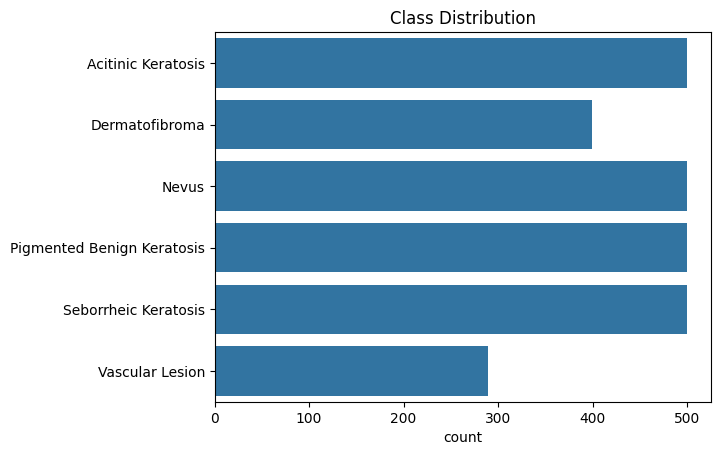

In [5]:
import pandas as pd
label_counts = pd.Series(root_labels).value_counts()
print(label_counts)

sns.countplot(y=root_labels)
plt.title("Class Distribution")
plt.show()


In [6]:
x_arr = np.array(root_images, dtype=np.float32)

y_arr = tf.one_hot(
    [classes.index(lbl) for lbl in root_labels],
    num_classes
).numpy()

print(x_arr.shape, y_arr.shape)


(2688, 224, 224, 3) (2688, 6)


In [7]:
import keras_cv
image_per_class = 1000
mix_per_batch = 42

mixup = keras_cv.layers.Augmenter([keras_cv.layers.MixUp()])

root_label_df = pd.DataFrame({"dx": root_labels})
count_dict = {label: len(imgs) for label, imgs in data_dict.items()}

x_tensor = tf.constant(x_arr)
y_tensor = tf.constant(y_arr)

x_tensor_mix, y_tensor_mix = None, None

for label, count in count_dict.items():
    num_mix = ((image_per_class - count) // mix_per_batch) * mix_per_batch

    for _ in range(num_mix // mix_per_batch):
        idx = np.random.choice(
            root_label_df[root_label_df.dx == label].index,
            mix_per_batch,
            replace=False
        )

        mix_out = mixup({
            "images": tf.gather(x_tensor, idx),
            "labels": tf.gather(y_tensor, idx)
        })

        if x_tensor_mix is None:
            x_tensor_mix = mix_out["images"]
            y_tensor_mix = mix_out["labels"]
        else:
            x_tensor_mix = tf.concat([x_tensor_mix, mix_out["images"]], axis=0)
            y_tensor_mix = tf.concat([y_tensor_mix, mix_out["labels"]], axis=0)

x = np.concatenate([x_arr, x_tensor_mix.numpy()], axis=0)
y = np.concatenate([y_arr, y_tensor_mix.numpy()], axis=0)

print(x.shape, y.shape)

(5796, 224, 224, 3) (5796, 6)


In [8]:
from sklearn.model_selection import train_test_split
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)
print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)


Train: (4636, 224, 224, 3)
Validation: (580, 224, 224, 3)
Test: (580, 224, 224, 3)


In [9]:
from tensorflow.keras import layers,Model

# -------------------------------
# Channel Attention
# -------------------------------
def channel_attention(input_feature, ratio=8):
    channel = input_feature.shape[-1]

    shared_dense_1 = layers.Dense(channel // ratio, activation='relu')
    shared_dense_2 = layers.Dense(channel)

    avg_pool = layers.GlobalAveragePooling2D()(input_feature)
    avg_pool = layers.Reshape((1, 1, channel))(avg_pool)
    avg_pool = shared_dense_2(shared_dense_1(avg_pool))

    max_pool = layers.GlobalMaxPooling2D()(input_feature)
    max_pool = layers.Reshape((1, 1, channel))(max_pool)
    max_pool = shared_dense_2(shared_dense_1(max_pool))

    attention = layers.Activation('sigmoid')(avg_pool + max_pool)
    return layers.Multiply()([input_feature, attention])


# -------------------------------
# Spatial Attention (FIXED)
# -------------------------------
def spatial_attention(input_feature):
    avg_pool = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True)
    )(input_feature)

    max_pool = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True)
    )(input_feature)

    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])

    attention = layers.Conv2D(
        filters=1,
        kernel_size=7,
        padding='same',
        activation='sigmoid'
    )(concat)

    return layers.Multiply()([input_feature, attention])


# -------------------------------
# CBAM Block
# -------------------------------
def cbam_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x


In [10]:
from tensorflow.keras.applications import EfficientNetB0
def build_efficientnet_cbam(num_classes):

    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(224,224,3)
    )

    base_model.trainable = False

    x = base_model.output
    x = cbam_block(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    output = layers.Dense(num_classes, activation="softmax")(x)
    return Model(base_model.input, output)


In [11]:
from tensorflow.keras.applications import MobileNetV3Large
def build_mobilenetv3_cbam(num_classes):

    base_model = MobileNetV3Large(
        weights="imagenet",
        include_top=False,
        input_shape=(224,224,3)
    )

    base_model.trainable = False

    x = base_model.output
    x = cbam_block(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    output = layers.Dense(num_classes, activation="softmax")(x)
    return Model(base_model.input, output)


In [12]:
from tensorflow.keras.applications import ResNet50
def build_resnet_cbam(num_classes):

    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224,224,3)
    )

    base_model.trainable = False

    x = base_model.output
    x = cbam_block(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    output = layers.Dense(num_classes, activation="softmax")(x)
    return Model(base_model.input, output)


In [13]:
model_1 = build_efficientnet_cbam(num_classes)
model_1.load_weights("CBAM_EfficientNetB0_model_final.keras")
model_2 = build_mobilenetv3_cbam(num_classes)
model_2.load_weights("CBAM_mobilenetv3_model_final.keras")
model_3 = build_resnet_cbam(num_classes)
model_3.load_weights("CBAM_ResNet50_model_final.keras")


In [15]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense

def convert_to_logits_model(model):

    # take second last layer output
    x = model.layers[-2].output   # dropout output

    # recreate SAME dense layer without activation
    logits = Dense(
        units=model.layers[-1].units,
        activation=None,
        name="logits_layer"
    )(x)

    # build logits model
    logits_model = Model(inputs=model.input, outputs=logits)

    # copy weights from softmax dense layer
    logits_model.get_layer("logits_layer").set_weights(
        model.layers[-1].get_weights()
    )

    return logits_model


In [ ]:
model_1_logits = convert_to_logits_model(model_1)
model_2_logits = convert_to_logits_model(model_2)
model_3_logits = convert_to_logits_model(model_3)

In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_pre
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input as mob_pre
from tensorflow.keras.applications.resnet import preprocess_input as res_pre

# -------------------------------
# PREPROCESS: train / val / test
# -------------------------------
x_train_eff = eff_pre(x_train.copy())
x_train_mob = mob_pre(x_train.copy())
x_train_res = res_pre(x_train.copy())

x_val_eff = eff_pre(x_val.copy())
x_val_mob = mob_pre(x_val.copy())
x_val_res = res_pre(x_val.copy())

x_test_eff = eff_pre(x_test.copy())
x_test_mob = mob_pre(x_test.copy())
x_test_res = res_pre(x_test.copy())

In [30]:
# -------------------------------
# LOGITS PREDICTIONS
# -------------------------------
logits_1_train = model_1_logits.predict(x_train_eff, batch_size=32)
logits_2_train = model_2_logits.predict(x_train_mob, batch_size=32)
logits_3_train = model_3_logits.predict(x_train_res, batch_size=32)

logits_1_val = model_1_logits.predict(x_val_eff, batch_size=32)
logits_2_val = model_2_logits.predict(x_val_mob, batch_size=32)
logits_3_val = model_3_logits.predict(x_val_res, batch_size=32)

logits_1_test = model_1_logits.predict(x_test_eff, batch_size=32)
logits_2_test = model_2_logits.predict(x_test_mob, batch_size=32)
logits_3_test = model_3_logits.predict(x_test_res, batch_size=32)

y_train_true = np.argmax(y_train, axis=1)
y_val_true   = np.argmax(y_val, axis=1)
y_test_true  = np.argmax(y_test, axis=1)

145/145 ━━━━━━━━━━━━━━━━━━━━ 94s 618ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 71s 486ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 228s 2s/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 11s 578ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 342ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 12s 614ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 354ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step


In [35]:
import tensorflow as tf

# convert TRAIN logits → probabilities
preds_1_train = tf.nn.softmax(logits_1_train).numpy()
preds_2_train = tf.nn.softmax(logits_2_train).numpy()
preds_3_train = tf.nn.softmax(logits_3_train).numpy()

# convert VAL logits → probabilities (if not already defined)
preds_1_val = tf.nn.softmax(logits_1_val).numpy()
preds_2_val = tf.nn.softmax(logits_2_val).numpy()
preds_3_val = tf.nn.softmax(logits_3_val).numpy()

# convert TEST logits → probabilities (if not already defined)
preds_1_test = tf.nn.softmax(logits_1_test).numpy()
preds_2_test = tf.nn.softmax(logits_2_test).numpy()
preds_3_test = tf.nn.softmax(logits_3_test).numpy()


In [36]:
from sklearn.metrics import accuracy_score

soft_vote_val = (preds_1_val + preds_2_val + preds_3_val) / 3
soft_vote_val_preds = np.argmax(soft_vote_val, axis=1)

print("Validation Soft Voting Accuracy:",
      accuracy_score(y_val_true, soft_vote_val_preds))

soft_vote_test = (preds_1_test + preds_2_test + preds_3_test) / 3
soft_vote_test_preds = np.argmax(soft_vote_test, axis=1)

print("TEST Soft Voting Accuracy:",
      accuracy_score(y_test_true, soft_vote_test_preds))


Validation Soft Voting Accuracy: 0.9758620689655172
TEST Soft Voting Accuracy: 0.9586206896551724


In [37]:
# -------------------------------
# DUAL STACKING INPUT
# -------------------------------
meta_X_train = np.concatenate([
    logits_1_train, logits_2_train, logits_3_train,
    preds_1_train, preds_2_train, preds_3_train
], axis=1)

meta_X_val = np.concatenate([
    logits_1_val, logits_2_val, logits_3_val,
    preds_1_val, preds_2_val, preds_3_val
], axis=1)

meta_X_test = np.concatenate([
    logits_1_test, logits_2_test, logits_3_test,
    preds_1_test, preds_2_test, preds_3_test
], axis=1)


In [38]:
# -------------------------------
# SCALING (IMPORTANT)
# -------------------------------
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

meta_X_train = scaler.fit_transform(meta_X_train)
meta_X_val   = scaler.transform(meta_X_val)
meta_X_test  = scaler.transform(meta_X_test)


In [39]:
# -------------------------------
# META MODEL TRAINING
# -------------------------------
from sklearn.linear_model import LogisticRegression

meta_model = LogisticRegression(max_iter=2000)

meta_model.fit(meta_X_train, y_train_true)


LogisticRegression(max_iter=2000)

In [40]:
stacked_val_preds = meta_model.predict(meta_X_val)

print("Validation Hybrid Stacking Accuracy:",
      accuracy_score(y_val_true, stacked_val_preds))


Validation Hybrid Stacking Accuracy: 0.9775862068965517


In [41]:
stacked_test_preds = meta_model.predict(meta_X_test)

print("TEST Hybrid Stacking Accuracy:",
      accuracy_score(y_test_true, stacked_test_preds))


TEST Hybrid Stacking Accuracy: 0.9689655172413794


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test_true, stacked_test_preds))

              precision    recall  f1-score   support

           0       0.93      0.96      0.94        96
           1       0.94      0.94      0.94        99
           2       1.00      1.00      1.00        96
           3       1.00      0.99      0.99        96
           4       0.96      0.93      0.94        97
           5       0.99      1.00      0.99        96

    accuracy                           0.97       580
   macro avg       0.97      0.97      0.97       580
weighted avg       0.97      0.97      0.97       580



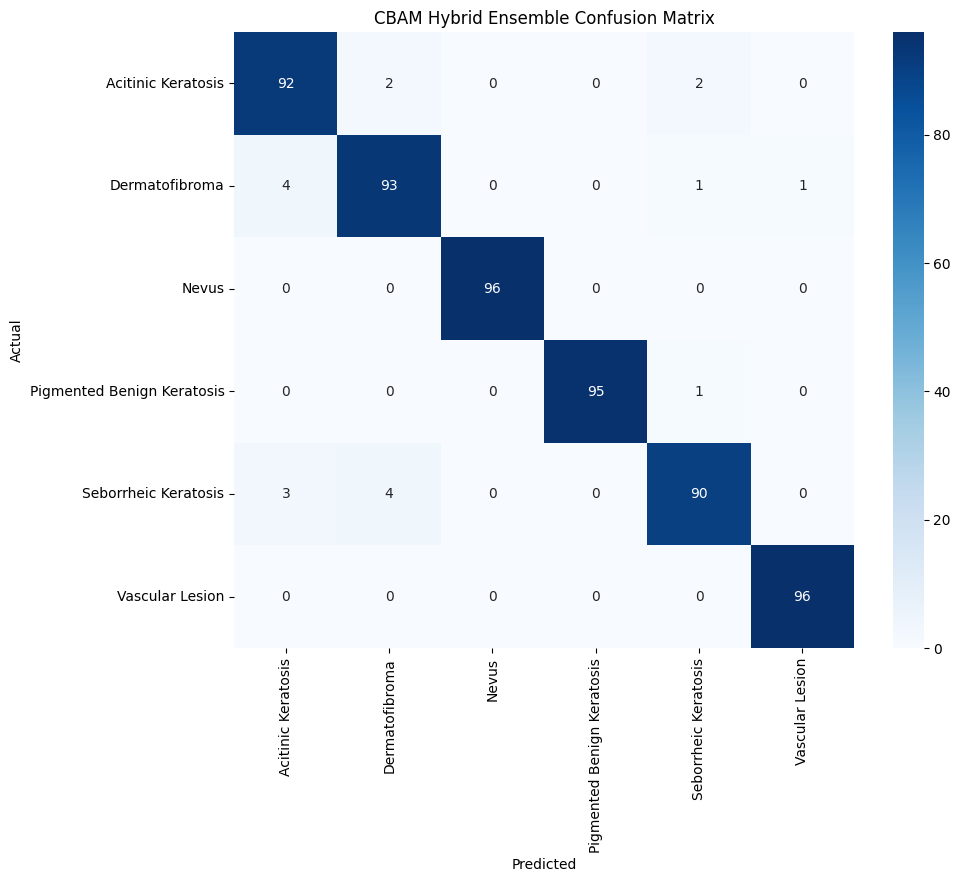

In [43]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_true, stacked_test_preds)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, cmap="Blues",
            xticklabels=classes,
            yticklabels=classes)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CBAM Hybrid Ensemble Confusion Matrix")
plt.show()

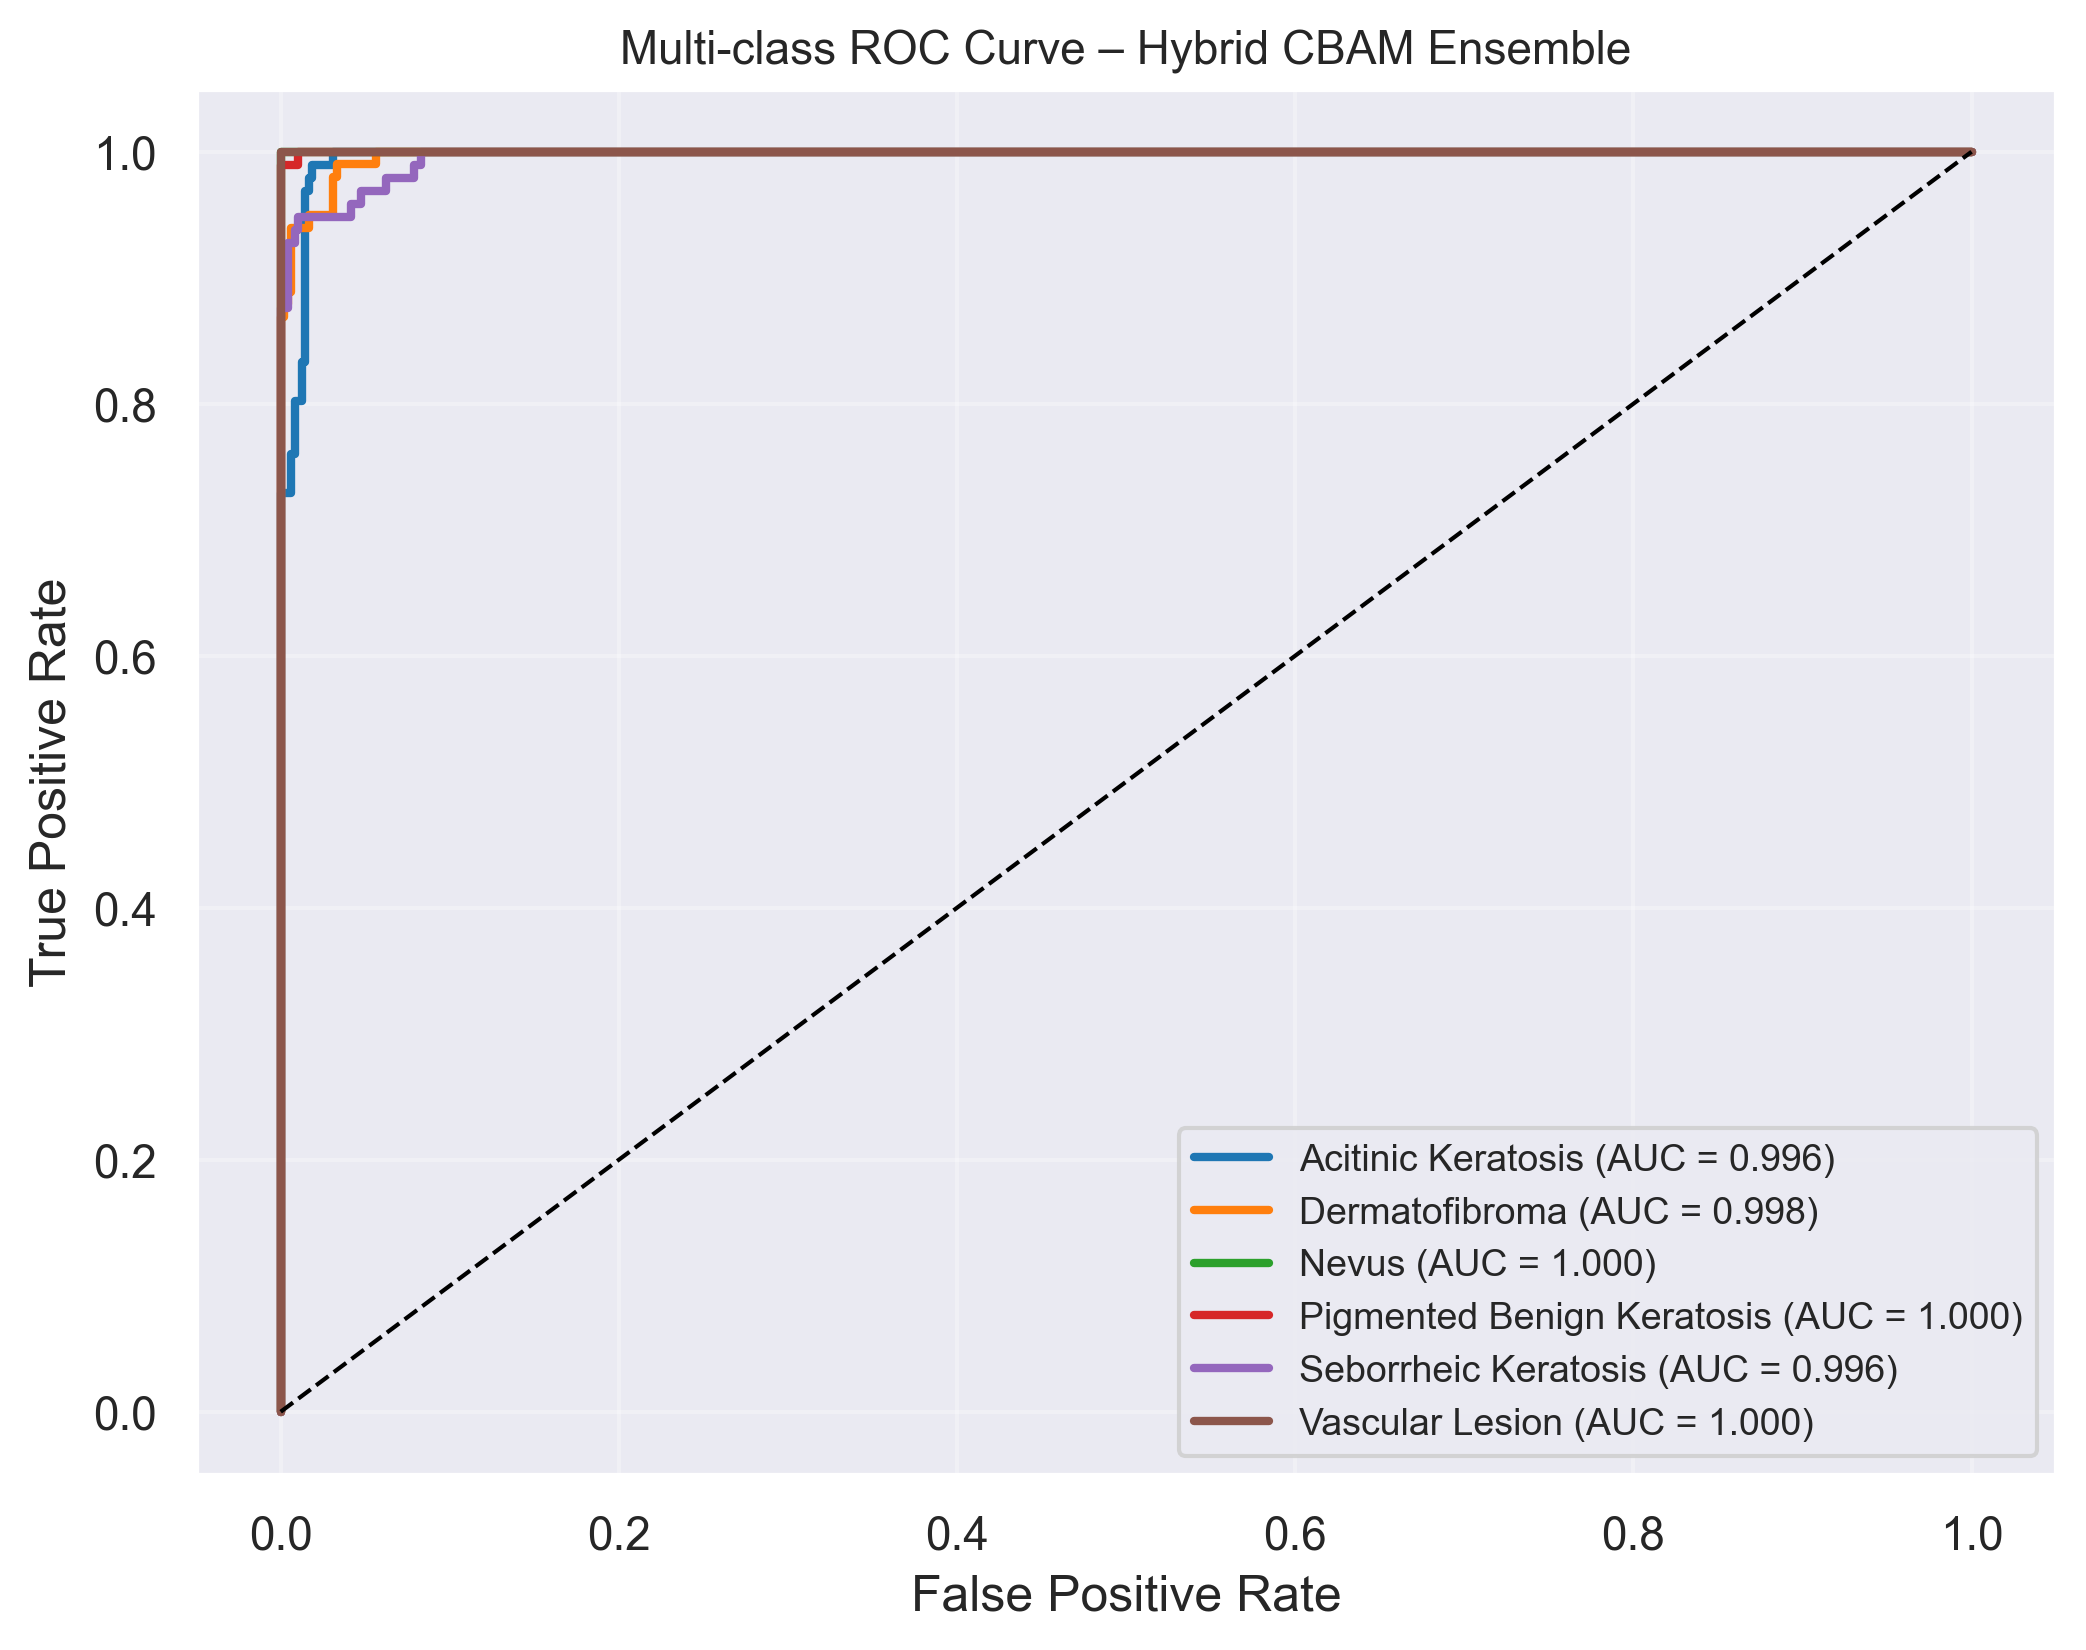

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

# Apply SAME design as MobileNet plot
sns.set_style("darkgrid")
sns.set_context("notebook")

plt.figure(figsize=(8, 6), dpi=300)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], linewidth=2,
             label=f"{classes[i]} (AUC = {roc_auc[i]:.3f})")

# Random classifier line
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("Multi-class ROC Curve – Hybrid CBAM Ensemble", fontsize=11)

plt.legend(loc="lower right", fontsize=9)

plt.grid(alpha=0.3)

plt.savefig("roc_curve_hybrid_seaborn_style.png", dpi=300, bbox_inches='tight')

plt.show()


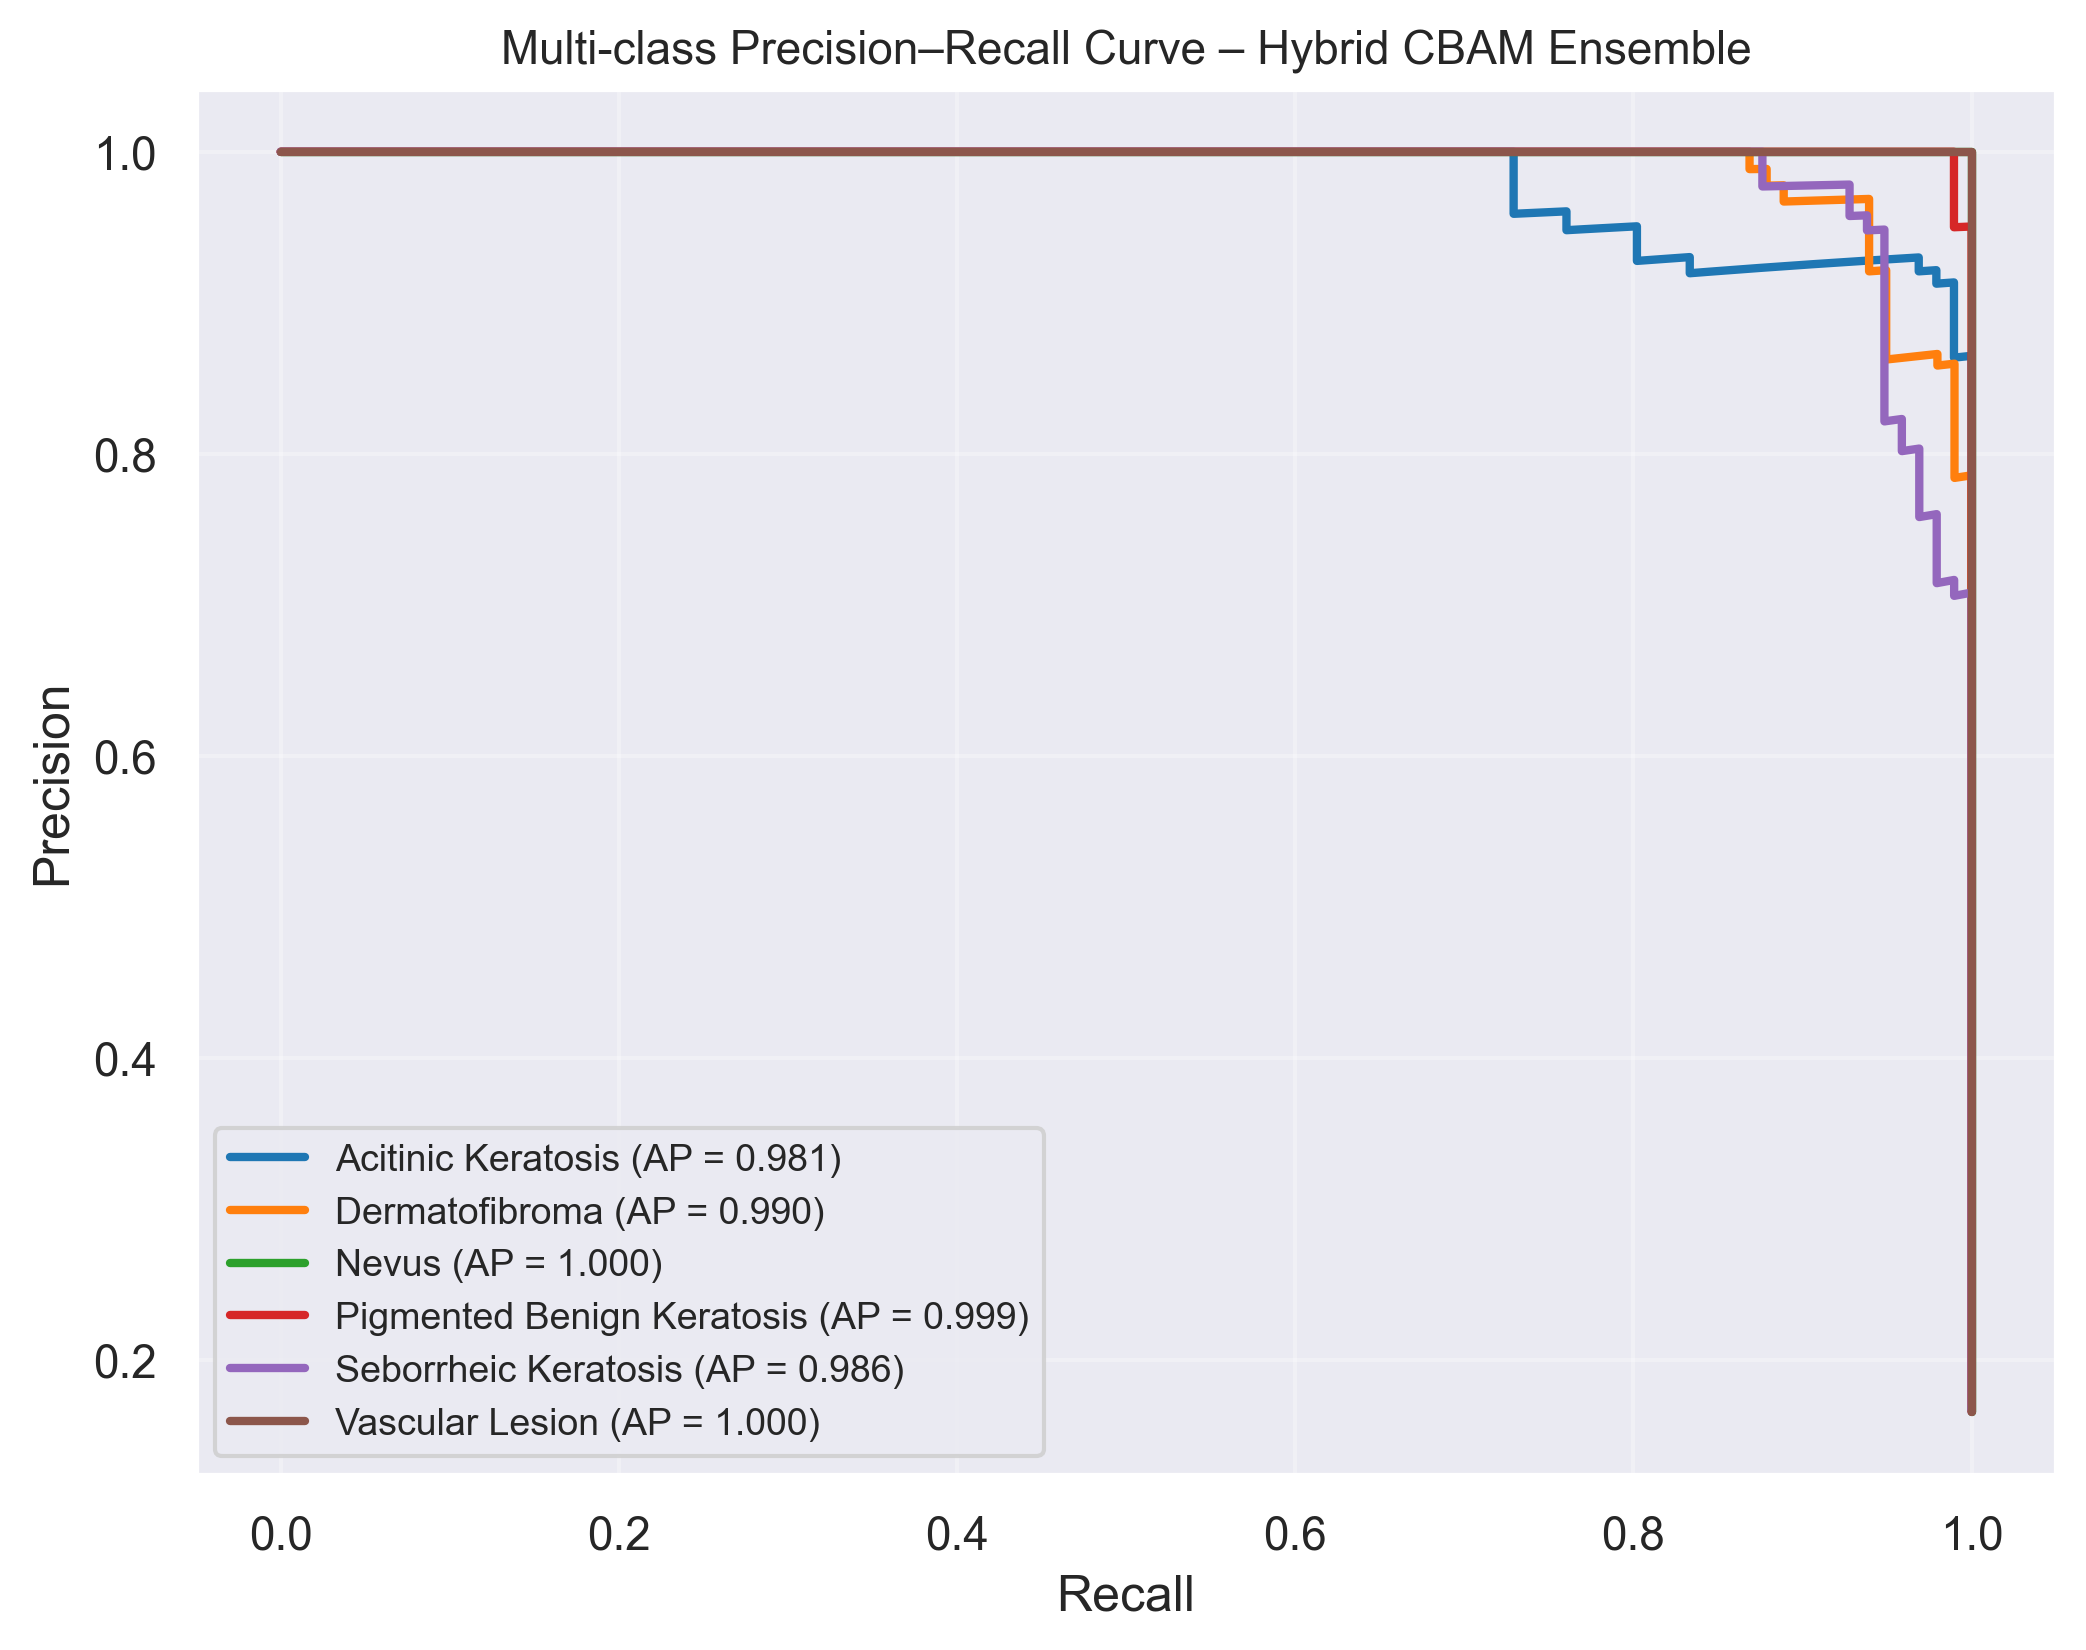

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Predict probabilities from meta model
y_score = meta_model.predict_proba(meta_X_test)

# True labels
y_true = np.argmax(y_test, axis=1)
n_classes = y_test.shape[1]

# Binarize
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# Compute PR
precision = dict()
recall = dict()
avg_precision = dict()

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_score[:, i])
    avg_precision[i] = average_precision_score(y_true_bin[:, i], y_score[:, i])

# Plot
plt.figure(figsize=(8,6), dpi=300)

for i in range(n_classes):
    plt.plot(recall[i], precision[i], linewidth=2,
             label=f"{classes[i]} (AP = {avg_precision[i]:.3f})")

plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.title("Multi-class Precision–Recall Curve – Hybrid CBAM Ensemble", fontsize=11)

plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

plt.savefig("pr_curve_hybrid.png", dpi=300, bbox_inches='tight')
plt.show()


In [51]:
import joblib

# save logistic regression meta model
joblib.dump(meta_model, "hybrid_cbam_meta_model.pkl")

print("Meta model saved successfully.")


Meta model saved successfully.
